# 07 · Qué información importa

**Punto de partida.** El MDA es el ancla (notebook 05) y, desde el notebook 06, todos los modelos se entrenan con las filas de Monclova y de los 64 nodos. La base de todos usa lo mismo: los rezagos del MTR (de *d−8* en adelante) y el MDA con su error. La pregunta ahora es qué más darles.

**Cómo se plantea.** Con dos modelos que aprenden distinto, LEAR (lineal) y el gradient boosting (GB, árboles):

1. se agregan por separado las variables **exógenas** (calendario, clima, combustibles, Texas, estado del sistema, información pública del día anterior, congestión) y las de **modelado estadístico** del MTR y del MDA (estadísticas móviles, varias escalas, días análogos, red en el espacio, complejidad y correlación);
2. se les dan **todas** juntas (744 columnas);
3. se mide **qué pierde** cada uno si a ese modelo completo se le quita una familia;
4. como mucha información se repite, se **resume con PCA** y se vuelve a probar.

Todo en desarrollo (julio a diciembre de 2024), en MXN/MWh y en % contra el MDA (221.6) o contra la versión que se indica. Los cálculos pesados se hicieron en un servidor (`src/pml/servidor.py`); aquí se leen de caché.

In [1]:
import os
for k in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'): os.environ[k] = '1'   # evita sobresuscripción en procesos paralelos
import sys, warnings, time, pickle
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dataclasses import replace
from pml import plotstyle as ps
ps.aplicar()
FIG = ROOT / 'reports/figures'; REP = ROOT / 'reports'

from pml import features2 as f2, exp, multinodo as mn, referencias as rf
from pml.todo import TODO, NUCLEO, CALENDARIO, FAMILIAS, K_PC
from pml.servidor import GRUPOS
R = rf.cargar()
cb, Y, X = R.cb, R.Y, R.X
cbn = f2.con_nodos(cb)                                             # el contexto con los precios de los nodos (lo usan las variables de la red)
DEV, DIAS = exp.idx_dev(), exp.dias_eval(R.c0)
m = R.mae                                                          # MAE de desarrollo, en MXN/MWh
CACHE = ROOT / 'data/processed/exp_cache'
Xtb = f2._t(cb)[1]
inv_s = lambda P: f2.inv(P + Xtb.loc[P.index], cb)                 # del error pronosticado (escala del proyecto) al precio
tabla = lambda filas, archivo: (lambda T: (display(T), T.to_csv(REP / archivo)))(exp.comparar(Y, filas, X, registrar_como='nb07'))
# LEAR y GB entrenados con Monclova y los 64 nodos en cada paso. Se calcularon en el servidor (src/pml/servidor.py) y aquí se leen de caché
lear = lambda grupos, dias=DIAS, nombre='lear_red', comp=None: exp.pronostico(cb, mn.lear(cbn, dias, grupos=grupos, troncal=True, nombre=nombre, comp=comp, k=K_PC))[0]
gb = lambda archivo: inv_s(pickle.loads((CACHE / archivo).read_bytes()))
L = {p: lear(GRUPOS[p], comp='nucleo' if p == 'pca' else None) for p in GRUPOS}
G = {p: gb(f'esc_gb_{p}.pkl') for p in GRUPOS}

def barras(perdida: pd.Series, titulo, archivo, ax=None):
    """Barras horizontales: cuánto sube el error (%) sin cada familia. Negativo = el modelo mejora sin ella."""
    s = perdida.sort_values()
    ax = ax or plt.subplots(figsize=(9, 0.42 * len(s) + 1))[1]
    ax.barh(s.index, s.values, color=[ps.NARANJA if v > 0.5 else (ps.AZUL if v < -0.5 else ps.GRIS) for v in s.values], height=0.6)
    esc = max(s.abs().max(), 0.5); off = 0.02 * esc                    # separación de las etiquetas, en proporción a la escala
    for i, v in enumerate(s.values):
        ax.text(v + (off if v >= 0 else -off), i, f'{v:+.1f}%', va='center', ha='left' if v >= 0 else 'right', fontsize=8)
    ax.set_xlim(min(s.min(), 0) - 0.25 * esc, max(s.max(), 0) + 0.25 * esc)
    ax.axvline(0, color=ps.GRIS, lw=0.8); ax.set_title(titulo); ax.set_xlabel('cambio del error en desarrollo al quitarla (%)')
    ax.figure.tight_layout(); ax.figure.savefig(FIG / archivo, bbox_inches='tight')
    return ax

## 1. Dos tipos de información

Las exógenas vienen de fuera del mercado: lo que el notebook 03 encontró disponible en *d−1*. El modelado estadístico, en cambio, no trae información nueva: describe con más riqueza cómo se ha movido el MTR y cómo se ha equivocado el MDA. Por ejemplo, promedios a varias escalas, qué tan al azar se mueve la serie (entropía), si las rachas persisten (exponente de Hurst) o si las horas del día se mueven juntas. La figura muestra ocho de estas medidas, para el error del MDA (izquierda) y para el MTR (derecha).

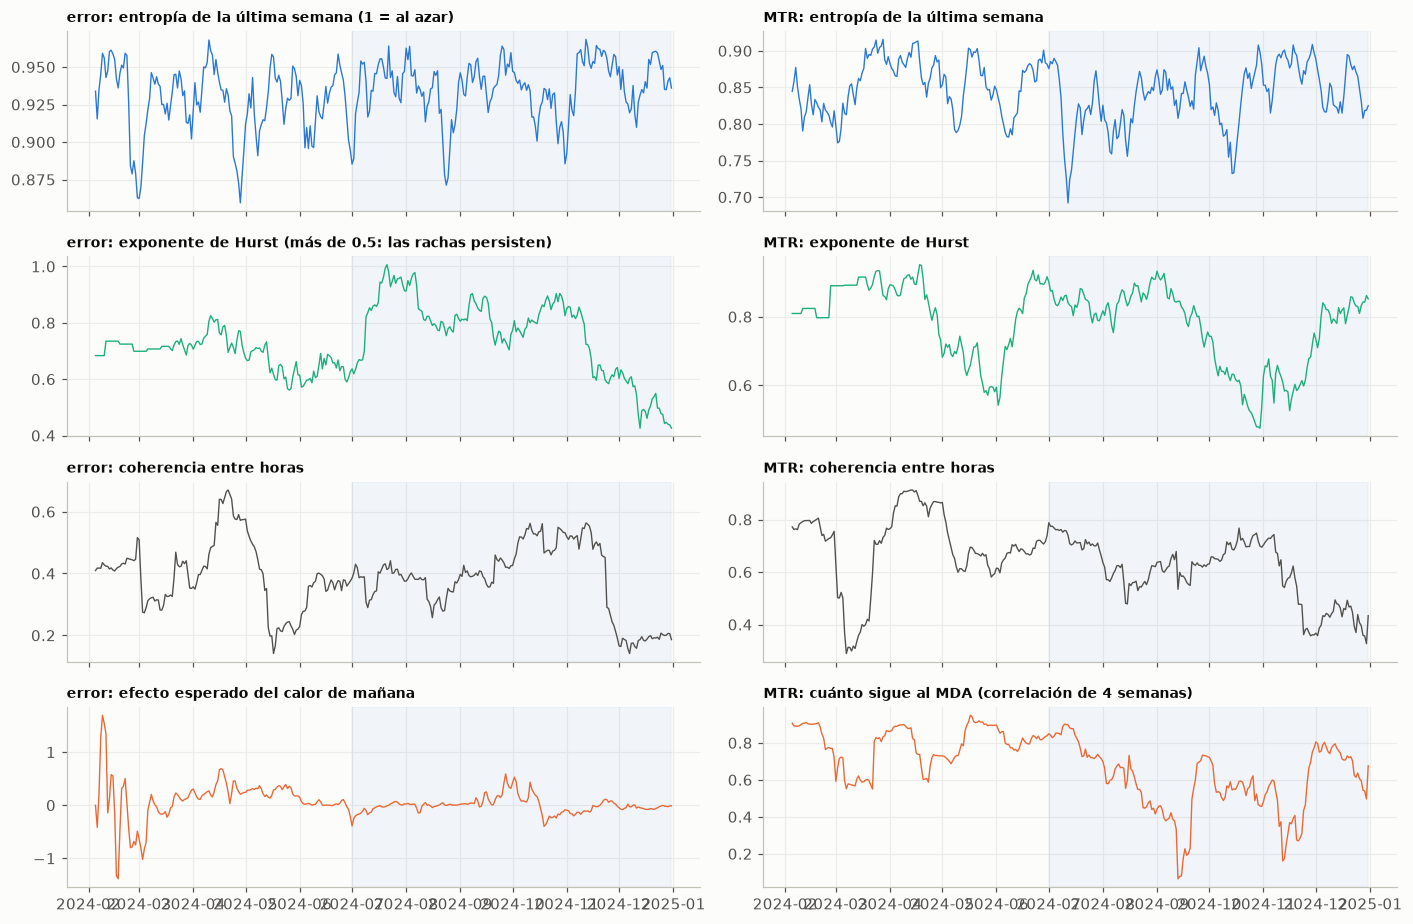

,correlación MTR vs error
entropia7,0.23
entropia28,-0.10
hurst84,0.08
asimetria28,0.65
curtosis28,0.90
coherencia_horas28,0.62
volvol28,0.75
estabilidad_perfil,0.30


In [2]:
# Ocho variables de G15 y G16 a lo largo del tiempo (el desarrollo está sombreado): a la izquierda, del error del MDA; a la derecha, del MTR
F15, _ = f2.construir(f2.con_nodos(cb), ['G15', 'G16']); F15 = F15.loc[:'2024-12-31']        # solo se dibuja hasta el fin del desarrollo
VARS16 = [[('spr_entropia7', 'error: entropía de la última semana (1 = al azar)', ps.AZUL), ('mtr_entropia7', 'MTR: entropía de la última semana', ps.AZUL)],
          [('spr_hurst84', 'error: exponente de Hurst (más de 0.5: las rachas persisten)', ps.AQUA), ('mtr_hurst84', 'MTR: exponente de Hurst', ps.AQUA)],
          [('coherencia_horas28', 'error: coherencia entre horas', ps.GRIS), ('mtr_coherencia_horas28', 'MTR: coherencia entre horas', ps.GRIS)],
          [('spr_calor_efecto', 'error: efecto esperado del calor de mañana', ps.NARANJA), ('mtr_sigue_mda28', 'MTR: cuánto sigue al MDA (correlación de 4 semanas)', ps.NARANJA)]]
fig, axs = plt.subplots(4, 2, figsize=(13, 8.5), sharex=True)
for fila, ejes in zip(VARS16, axs):
    for (col, tit, cc), ax in zip(fila, ejes):
        ax.plot(F15.index, F15[col], color=cc, lw=0.9); ax.set_title(tit, fontsize=9); ax.axvspan(f2.DEV_INI, f2.DEV_FIN, color=ps.AZUL, alpha=0.05)
fig.tight_layout(); fig.savefig(FIG / '07_complejidad.png'); plt.show()
# ¿Se parece la complejidad del MTR a la de su error? Correlación entre cada medida del MTR y su gemela del error
PAR = [('mtr_entropia7', 'spr_entropia7'), ('mtr_entropia28', 'spr_entropia28'), ('mtr_hurst84', 'spr_hurst84'), ('mtr_asimetria28', 'spr_asimetria28'),
       ('mtr_curtosis28', 'spr_curtosis28'), ('mtr_coherencia_horas28', 'coherencia_horas28'), ('mtr_volvol28', 'spr_volvol28'), ('mtr_estabilidad_perfil', 'estabilidad_perfil')]
display(pd.DataFrame({'correlación MTR vs error': {a.replace('mtr_', ''): F15[a].corr(F15[b], method='spearman') for a, b in PAR}}).round(2))

Las medidas cambian a lo largo del año. La persistencia del error (Hurst) sube a cerca de 1 al empezar el desarrollo y baja a 0.4 en diciembre; la coherencia entre horas del error cae a la mitad en diciembre; y entre septiembre y diciembre hay semanas en que el MTR casi deja de seguir al MDA (correlación de 4 semanas cerca de 0.1). Las medidas de colas del MTR se parecen mucho a las de su error (curtosis 0.90, volatilidad de la volatilidad 0.75, asimetría 0.65); las de entropía y persistencia, poco (0.23 y 0.08).

El estado del mercado no es fijo, y el MTR trae por sí mismo información sobre qué tan estable es el momento, en parte distinta de la que trae el error del MDA. Falta ver si a un modelo le sirve.

## 2. ¿Ayudan las exógenas o el modelado estadístico?

In [3]:
# Sobre la base con 64 nodos (rezagos del MTR, MDA y su error), por separado: las exógenas y el modelado estadístico del MTR y del MDA
filas = [('referencias', 'MDA', X, None)]
for k, P in (('LEAR', L), ('GB', G)):
    filas += [(k, f'{k} · base con 64 nodos', P['nodos'], None), (k, f'{k} · + exógenas', P['exogenas'], f'{k} · base con 64 nodos'),
              (k, f'{k} · + modelado estadístico', P['estadistico'], f'{k} · base con 64 nodos')]
tabla(filas, '07_ramas_dev.csv')

MAE  vs MDA (%)  \
grupo       modelo                                             
referencias MDA                            221.6         0.0   
LEAR        LEAR · base con 64 nodos       218.8        -1.3   
            LEAR · + exógenas              228.0         2.9   
            LEAR · + modelado estadístico  220.1        -0.7   
GB          GB · base con 64 nodos         222.3         0.3   
            GB · + exógenas                224.9         1.5   
            GB · + modelado estadístico    218.4        -1.5   

                                                         referencia  \
grupo       modelo                                                    
referencias MDA                                                       
LEAR        LEAR · base con 64 nodos                                  
            LEAR · + exógenas              LEAR · base con 64 nodos   
            LEAR · + modelado estadístico  LEAR · base con 64 nodos   
GB          GB · base con 64 nodos                                    
            GB · + exógenas                  GB · base con 64 nodos   
            GB · + modelado estadístico      GB · base con 64 nodos   

                                          vs referencia (%) meses mejor      p  
grupo       modelo                                                              
referencias MDA                                                                 
LEAR        LEAR · base con 64 nodos                                            
            LEAR · + exógenas                           4.2      2 de 6  0.051  
            LEAR · + modelado estadístico               0.6      2 de 6  0.006  
GB          GB · base con 64 nodos                                              
            GB · + exógenas                             1.1      1 de 6  0.782  
            GB · + modelado estadístico                -1.8      2 de 6  0.097

(None, None)

Se ve lo siguiente:

- **LEAR:** su base con 64 nodos tiene 218.8 (−1.3% contra el MDA). Las exógenas lo empeoran 4.2% (228.0); casi todo eso es un solo día, el 12 de septiembre de 2024, en que LEAR, que es lineal, extrapola alguna variable externa con un valor fuera de lo normal, y sin ese día el empeoramiento es de 1.7%. El modelado estadístico lo empeora poco (+0.6%, 220.1).
- **GB:** su base con 64 nodos tiene 222.3. Las exógenas lo empeoran 1.1% (224.9, mejor en solo 1 de 6 meses). El modelado estadístico lo mejora 1.8% (218.4), aunque concentrado: mejor en 2 de 6 meses y 1.1% sin el día en que más difieren.
- En la escalera (notebook 08) se ve que a LEAR en proporción le pasa lo mismo: el modelado estadístico lo deja casi igual (214.5 contra 215.2) y las exógenas lo empeoran (219.0).

Como bloque, las exógenas no ayudan a ningún modelo. El modelado estadístico ayuda al GB, que aprende de cómo se ha movido el precio, y casi nada a LEAR, que ya tiene lo esencial en el MDA y sus rezagos. Que un bloque no ayude no quiere decir que ninguna de sus familias aporte: eso se mide en la sección 4.

## 3. Todas las variables juntas

In [4]:
# Todas las variables juntas (744 columnas), contra la base y contra la mejor de las dos ramas
filas = [('referencias', 'MDA', X, None)]
for k, P in (('LEAR', L), ('GB', G)):
    rama = min(('exogenas', 'estadistico'), key=lambda r: m(P[r]))
    nom = {'exogenas': '+ exógenas', 'estadistico': '+ modelado estadístico'}[rama]
    filas += [(k, f'{k} · base con 64 nodos', P['nodos'], None), (k, f'{k} · {nom}', P[rama], None),
              (k, f'{k} · todas las variables', P['todas'], f'{k} · base con 64 nodos'), (k, f'{k} · todas contra {nom}', P['todas'], f'{k} · {nom}')]
tabla(filas, '07_todas_dev.csv')

MAE  vs MDA (%)  \
grupo       modelo                                                          
referencias MDA                                         221.6         0.0   
LEAR        LEAR · base con 64 nodos                    218.8        -1.3   
            LEAR · + modelado estadístico               220.1        -0.7   
            LEAR · todas las variables                  232.9         5.1   
            LEAR · todas contra + modelado estadístico  232.9         5.1   
GB          GB · base con 64 nodos                      222.3         0.3   
            GB · + modelado estadístico                 218.4        -1.5   
            GB · todas las variables                    220.0        -0.7   
            GB · todas contra + modelado estadístico    220.0        -0.7   

                                                                           referencia  \
grupo       modelo                                                                      
referencias MDA                                                                         
LEAR        LEAR · base con 64 nodos                                                    
            LEAR · + modelado estadístico                                               
            LEAR · todas las variables                       LEAR · base con 64 nodos   
            LEAR · todas contra + modelado estadístico  LEAR · + modelado estadístico   
GB          GB · base con 64 nodos                                                      
            GB · + modelado estadístico                                                 
            GB · todas las variables                           GB · base con 64 nodos   
            GB · todas contra + modelado estadístico      GB · + modelado estadístico   

                                                       vs referencia (%)  \
grupo       modelo                                                         
referencias MDA                                                            
LEAR        LEAR · base con 64 nodos                                       
            LEAR · + modelado estadístico                                  
            LEAR · todas las variables                               6.4   
            LEAR · todas contra + modelado estadístico               5.8   
GB          GB · base con 64 nodos                                         
            GB · + modelado estadístico                                    
            GB · todas las variables                                -1.0   
            GB · todas contra + modelado estadístico                 0.8   

                                                       meses mejor      p  
grupo       modelo                                                         
referencias MDA                                                            
LEAR        LEAR · base con 64 nodos                                       
            LEAR · + modelado estadístico                                  
            LEAR · todas las variables                      2 de 6  0.346  
            LEAR · todas contra + modelado estadístico      1 de 6  0.147  
GB          GB · base con 64 nodos                                         
            GB · + modelado estadístico                                    
            GB · todas las variables                        2 de 6   0.13  
            GB · todas contra + modelado estadístico        3 de 6  0.011

(None, None)

Con todas las variables, LEAR empeora 6.4% contra su base (232.9; 1.8% sin el 12 de septiembre). El GB queda 1.0% mejor que su base (220.0), pero 0.8% peor que con solo el modelado estadístico (218.4).

Dar todo no suma lo bueno de cada bloque. A LEAR le estorba: con ~300 días por nodo y 744 columnas, el LASSO no alcanza a apagar lo que sobra y algunos días extrapola mal. El GB elige mejor entre muchas variables, pero tampoco gana algo al agregar las exógenas al modelado estadístico.

## 4. ¿Qué información importa? Lo que pierde cada modelo sin cada familia

A cada modelo con todas las variables se le quita una familia, se reentrena y se mide cuánto sube su error. Si sube, la familia aportaba algo que el resto no tiene. Un solo día puede mover el promedio (a LEAR sin combustibles, el 12 de septiembre le sube el error diario en más de 9,000 MXN/MWh), así que la figura usa el cambio sin el día en que más difieren los dos pronósticos; la tabla muestra las dos versiones.

MAE  vs MDA (%)  \
grupo modelo                                                                  
LEAR  LEAR · todas las variables                          232.9         5.1   
      LEAR sin rezagos del MTR                            233.0         5.1   
      LEAR sin MDA y su error                             235.8         6.4   
      LEAR sin estadísticas móviles y varias escalas      228.1         2.9   
      LEAR sin complejidad y correlación del error de...  232.8         5.0   
      LEAR sin complejidad y correlación del MTR          232.9         5.1   
      LEAR sin la red: congestión y red en el espacio     220.6        -0.5   
      LEAR sin días análogos                              232.9         5.1   
      LEAR sin calendario y vacaciones                    230.9         4.2   
      LEAR sin clima                                      235.4         6.2   
      LEAR sin combustibles, gas y Texas                  284.9        28.6   
      LEAR sin estado del sistema e información pública   236.6         6.8   
GB    GB · todas las variables                            220.0        -0.7   
      GB sin rezagos del MTR                              220.4        -0.6   
      GB sin MDA y su error                               221.4        -0.1   
      GB sin estadísticas móviles y varias escalas        223.6         0.9   
      GB sin complejidad y correlación del error del MDA  220.6        -0.5   
      GB sin complejidad y correlación del MTR            220.2        -0.7   
      GB sin la red: congestión y red en el espacio       224.0         1.1   
      GB sin días análogos                                222.4         0.4   
      GB sin calendario y vacaciones                      222.4         0.3   
      GB sin clima                                        219.4        -1.0   
      GB sin combustibles, gas y Texas                    218.6        -1.3   
      GB sin estado del sistema e información pública     227.0         2.4   

                                                                          referencia  \
grupo modelo                                                                           
LEAR  LEAR · todas las variables                                                       
      LEAR sin rezagos del MTR                            LEAR · todas las variables   
      LEAR sin MDA y su error                             LEAR · todas las variables   
      LEAR sin estadísticas móviles y varias escalas      LEAR · todas las variables   
      LEAR sin complejidad y correlación del error de...  LEAR · todas las variables   
      LEAR sin complejidad y correlación del MTR          LEAR · todas las variables   
      LEAR sin la red: congestión y red en el espacio     LEAR · todas las variables   
      LEAR sin días análogos                              LEAR · todas las variables   
      LEAR sin calendario y vacaciones                    LEAR · todas las variables   
      LEAR sin clima                                      LEAR · todas las variables   
      LEAR sin combustibles, gas y Texas                  LEAR · todas las variables   
      LEAR sin estado del sistema e información pública   LEAR · todas las variables   
GB    GB · todas las variables                                                         
      GB sin rezagos del MTR                                GB · todas las variables   
      GB sin MDA y su error                                 GB · todas las variables   
      GB sin estadísticas móviles y varias escalas          GB · todas las variables   
      GB sin complejidad y correlación del error del MDA    GB · todas las variables   
      GB sin complejidad y correlación del MTR              GB · todas las variables   
      GB sin la red: congestión y red en el espacio         GB · todas las variables   
      GB sin días análogos                                  GB · todas las variables   
      GB sin calendario y vacaciones                        GB · toda

todos los días       \
                                                      LEAR   GB   
rezagos del MTR                                        0.1  0.2   
MDA y su error                                         1.3  0.6   
estadísticas móviles y varias escalas                 -2.0  1.6   
complejidad y correlación del error del MDA           -0.0  0.3   
complejidad y correlación del MTR                      0.0  0.1   
la red: congestión y red en el espacio                -5.3  1.8   
días análogos                                          0.0  1.1   
calendario y vacaciones                               -0.8  1.1   
clima                                                  1.1 -0.3   
combustibles, gas y Texas                             22.3 -0.6   
estado del sistema e información pública               1.6  3.2   

                                            sin el día más distinto       
                                                               LEAR   GB  
rezagos del MTR                                                 0.1  0.1  
MDA y su error                                                  1.2  1.3  
estadísticas móviles y varias escalas                          -0.1  1.4  
complejidad y correlación del error del MDA                     0.0  0.3  
complejidad y correlación del MTR                              -0.0  0.1  
la red: congestión y red en el espacio                         -0.9  1.5  
días análogos                                                   0.0  1.0  
calendario y vacaciones                                        -0.4  0.9  
clima                                                           0.3 -0.1  
combustibles, gas y Texas                                       0.8 -0.4  
estado del sistema e información pública                        0.4  2.5

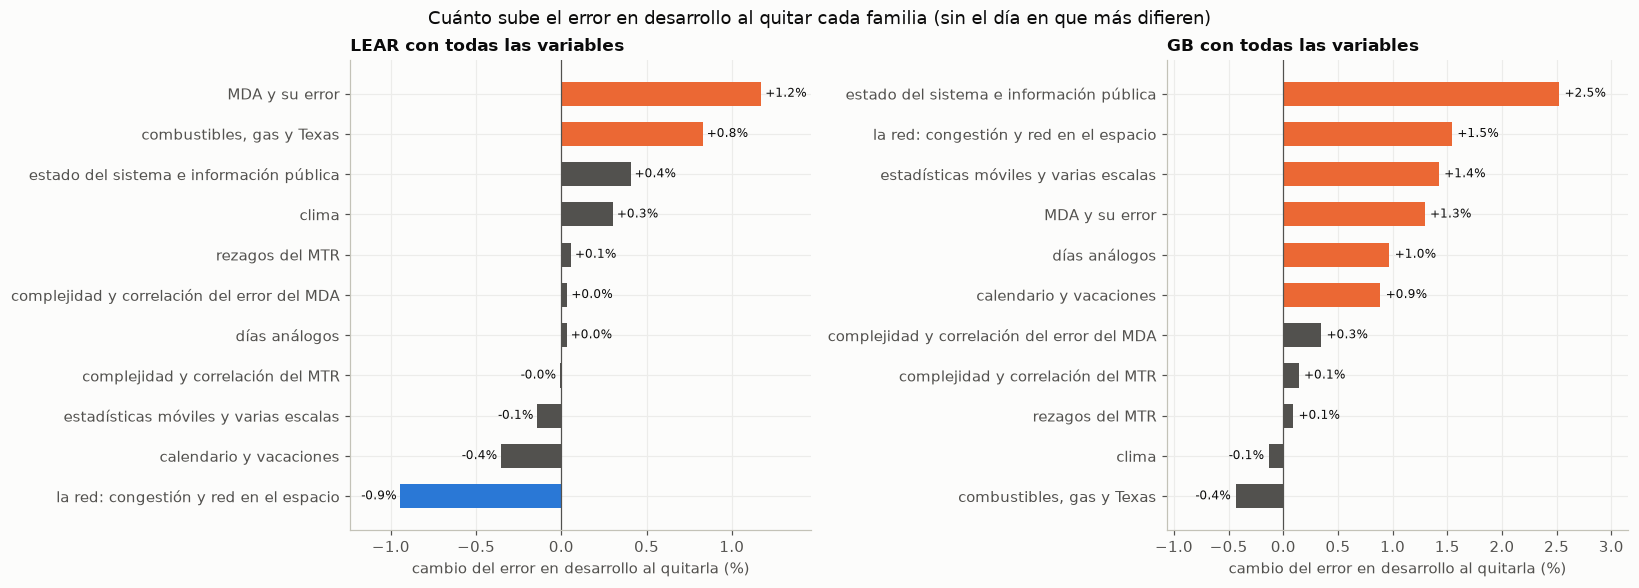

In [5]:
# Qué pierde cada modelo si se le quita una familia: el modelo con todas las variables, reentrenado sin ella (solo en desarrollo;
# calculado en el servidor). Positivo = el error sube sin esa familia, es decir, la familia aportaba
SIN_L = {f: lear([g for g in TODO if g not in v], DEV, 'imp_lear') for f, v in FAMILIAS.items()}
SIN_G = {f: gb(f'imp_gb_{i}.pkl') for i, f in enumerate(FAMILIAS)}
tabla([('LEAR', 'LEAR · todas las variables', L['todas'], None)] + [('LEAR', f'LEAR sin {f}', P, 'LEAR · todas las variables') for f, P in SIN_L.items()]
      + [('GB', 'GB · todas las variables', G['todas'], None)] + [('GB', f'GB sin {f}', P, 'GB · todas las variables') for f, P in SIN_G.items()],
      '07_importancia_dev.csv')
# Un solo día puede mover todo el promedio (LEAR con todas las variables se dispara el 12 de septiembre de 2024), así que también se
# mide el cambio sin el día en que más difieren los dos pronósticos. Las barras usan esa versión
ed = lambda P: (Y - P).abs().loc[DEV].mean(axis=1)
def cambio(P, ref, sin_peor=False):
    k = DEV.drop((ed(P) - ed(ref)).abs().idxmax()) if sin_peor else DEV
    return 100 * ((Y - P).abs().loc[k].values.mean() / (Y - ref).abs().loc[k].values.mean() - 1)
PERD = pd.concat({'todos los días': pd.DataFrame({'LEAR': {f: cambio(P, L['todas']) for f, P in SIN_L.items()}, 'GB': {f: cambio(P, G['todas']) for f, P in SIN_G.items()}}),
                  'sin el día más distinto': pd.DataFrame({'LEAR': {f: cambio(P, L['todas'], True) for f, P in SIN_L.items()}, 'GB': {f: cambio(P, G['todas'], True) for f, P in SIN_G.items()}})}, axis=1)
display(PERD.round(1))
fig, axs = plt.subplots(1, 2, figsize=(15, 5.2))
barras(PERD['sin el día más distinto', 'LEAR'], 'LEAR con todas las variables', '07_importancia_familias.png', axs[0])
barras(PERD['sin el día más distinto', 'GB'], 'GB con todas las variables', '07_importancia_familias.png', axs[1])
fig.suptitle('Cuánto sube el error en desarrollo al quitar cada familia (sin el día en que más difieren)', y=1.02); plt.show()

Se observa lo siguiente (cambio sin el día más distinto; positivo = el error sube sin la familia):

- **LEAR:** lo que más pierde es el MDA y su error (+1.2%), seguido de los combustibles, el gas y Texas (+0.8%), el estado del sistema y la información pública (+0.4%) y el clima (+0.3%). Sin la red mejora (−0.9%) y sin el calendario también (−0.4%). Las medidas de complejidad, los análogos y los rezagos del MTR casi no cambian nada (±0.1%).
- **GB:** lo que más pierde es el estado del sistema y la información pública del día anterior (+2.5%), luego la red (+1.5%), las estadísticas móviles y varias escalas (+1.4%), el MDA y su error (+1.3%), los días análogos (+1.0%) y el calendario (+0.9%). La complejidad del error del MDA aporta un poco (+0.3%). Sin los combustibles mejora un poco (−0.4%) y el clima no le cambia nada (−0.1%).
- Con el promedio de todos los días, los números de LEAR cambian mucho por un solo día (sin combustibles, +22.3%; sin la red, −5.3%), lo que confirma que el LEAR con todo es inestable.

Lo que más importa a los dos es el MDA y su error, y al GB además la información que describe cómo se mueve el sistema y el precio: la red, las estadísticas móviles y los días parecidos. Algunas exógenas sí aportan, pero poco y según el modelo: los combustibles y el clima ayudan algo a LEAR y nada al GB; el estado del sistema y la información pública del día anterior son lo que más ayuda al GB. Las medidas de complejidad aportan muy poco por sí solas. Vale la pena explorar un poco las exógenas que aportan, pero lo que más rinde es modelar bien la historia del MTR y del MDA.

## 5. La información se repite: qué hay dentro de las componentes del PCA

,columnas,% de las columnas,% de la varianza retenida,peso en la componente 1 (%),componente donde más pesa
varias escalas,81,16.5,18.3,11.7,pc2
clima de la zona,72,14.7,14.0,25.8,pc7
congestión de la red,61,12.4,11.7,4.1,pc4
estadísticas móviles,51,10.4,10.8,10.8,pc5
MTR mismo día de la semana,48,9.8,10.7,13.2,pc10
red en el espacio,31,6.3,7.3,4.5,pc4
información pública del día anterior,33,6.7,5.8,7.5,pc13
días análogos,27,5.5,4.8,3.0,pc19
combustibles y tipo de cambio,16,3.3,3.4,3.5,pc17
clima nacional,18,3.7,3.4,4.6,pc19


varianza explicada por componente (%): 1: 23.7 2: 14.6 3: 7.4 4: 4.3 5: 4.0 6: 3.6 7: 2.9 8: 2.6 9: 2.1 10: 1.9 11: 1.7 12: 1.5 13: 1.3 14: 1.2 15: 1.2 16: 1.0 17: 1.0 18: 1.0 19: 0.9 20: 0.8 | total 79%
pc1 (23.7% de la varianza): +temp (clima de la zona), +mtr_l21 (MTR mismo día de la semana), +mtr_l28 (MTR mismo día de la semana), +ghi (clima de la zona), +red_spr_ewm7 (red en el espacio), +spr_ewm28 (varias escalas)
pc2 (14.6% de la varianza): +spr_ewm7 (varias escalas), +red_spr_ewm7 (red en el espacio), +spr_ewm28 (varias escalas), +mda_sorpresa (estadísticas móviles), −mtr_l28 (MTR mismo día de la semana), +an (días análogos)
pc3 (7.4% de la varianza): +spr_ewm28 (varias escalas), +spr_ewm7 (varias escalas), +an (días análogos), −mda_sorpresa (estadísticas móviles), +cngmda (congestión de la red), −temp (clima de la zona)
pc5 (4.0% de la varianza): +mda_sorpresa (estadísticas móviles), −red_spr_ewm7 (red en el espacio), −ghi (clima de la zona), +spr_ewm7 (varias escalas), −an (d

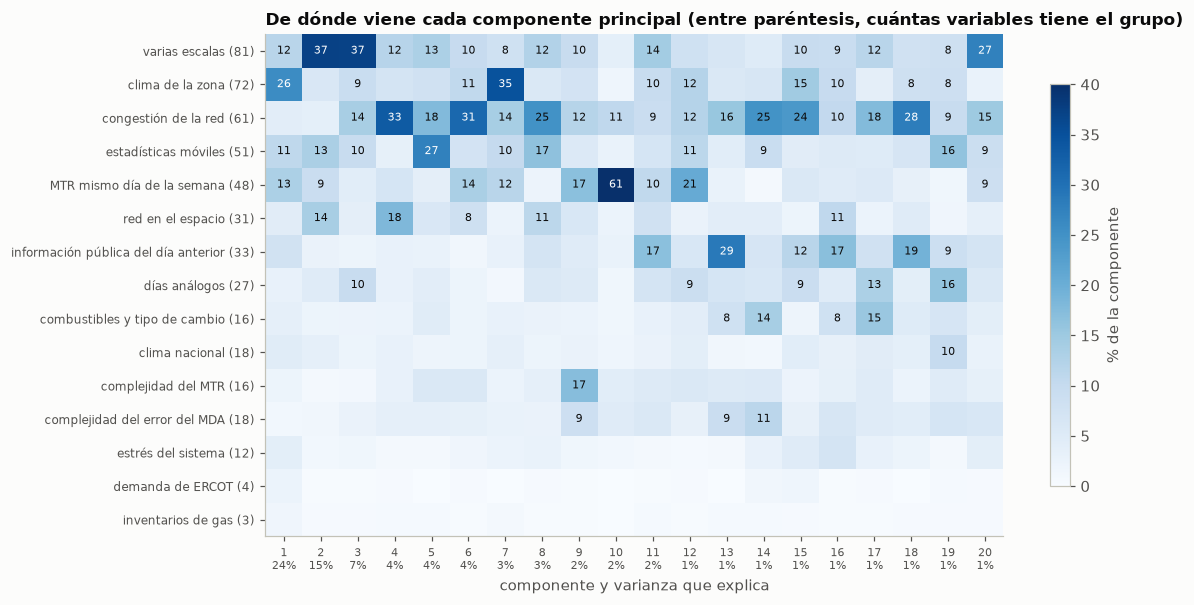

In [6]:
# Las cargas (loadings) de las 20 componentes: qué variables pesan en cada una. Se resume todo salvo los rezagos, el MDA y el calendario.
# Cada carga dice cuánto pesa una variable (estandarizada) en la componente; las cargas de una componente suman 1 al cuadrado,
# así que el cuadrado de una carga es la parte de la componente que le toca a esa variable.
import re
RESTO = [g for g in TODO if g not in NUCLEO + CALENDARIO]            # lo que entra al PCA
F728 = mn.apilar(cbn, RESTO, True, True)[0].drop(columns=['nodo', 'corredor']).sort_index()   # filas de Monclova y de los 64 nodos
G728 = f2.construir(cbn, RESTO)[1]
CARG, VAR = f2.cargas(F728, K_PC)
g = G728.reindex(CARG.columns)
base = lambda x: re.sub(r'_h\d+$', '', x)                                    # las 24 horas de una variable cuentan como una
# 1) cuánto explica cada componente, y de qué grupos viene
parte = (CARG ** 2).T.groupby(g.values).sum().T                               # fila = componente, columna = grupo; cada fila suma 1
ncols = g.value_counts()
resumen = pd.DataFrame({'columnas': ncols, '% de las columnas': 100 * ncols / ncols.sum(),
                        '% de la varianza retenida': 100 * (parte.mul(VAR, axis=0).sum() / VAR.sum()).reindex(ncols.index),
                        'peso en la componente 1 (%)': 100 * parte.loc['pc1'].reindex(ncols.index),
                        'componente donde más pesa': parte.idxmax().reindex(ncols.index)}).sort_values('% de la varianza retenida', ascending=False)
NOMBRE_G = {'G0': 'MTR de d−8 a d−14', 'G0dow': 'MTR mismo día de la semana', 'G1': 'calendario base', 'G2': 'MDA y su error', 'G4': 'estadísticas móviles',
            'G5': 'clima de la zona', 'G6': 'combustibles y tipo de cambio', 'G6e': 'demanda de ERCOT', 'G6g': 'inventarios de gas', 'G7': 'calendario ampliado',
            'G7v': 'vacaciones', 'G8': 'estrés del sistema', 'G9': 'información pública del día anterior', 'G10': 'congestión de la red', 'G11': 'clima nacional',
            'G12': 'días análogos', 'G13': 'varias escalas', 'G14': 'red en el espacio', 'G15': 'complejidad del error del MDA', 'G16': 'complejidad del MTR'}
nombre_g = lambda k: NOMBRE_G.get(k, k)
resumen.index = [nombre_g(k) for k in resumen.index]; parte.columns = [nombre_g(k) for k in parte.columns]; ncols.index = [nombre_g(k) for k in ncols.index]
resumen['componente donde más pesa'] = resumen['componente donde más pesa']
display(resumen.round(1))
print('varianza explicada por componente (%):', ' '.join(f'{k[2:]}: {100 * v:.1f}' for k, v in VAR.items()), f'| total {100 * VAR.sum():.0f}%')
# 2) las variables que más pesan en algunas componentes (primeras, intermedias y últimas)
for pc in ['pc1', 'pc2', 'pc3', 'pc5', 'pc8', 'pc12', 'pc20']:
    s = CARG.loc[pc]; v = s.groupby(base).apply(lambda x: (np.sqrt((x ** 2).sum()), np.sign(x.sum())))
    top = sorted(v.items(), key=lambda kv: -kv[1][0])[:6]
    print(f"{pc} ({100 * VAR[pc]:.1f}% de la varianza): " + ', '.join(f"{'+' if sg > 0 else '−'}{k} ({nombre_g(g[[c for c in s.index if base(c) == k][0]])})" for k, (w, sg) in top))
# 3) mapa de calor: de qué grupos viene cada componente
orden = resumen.index.tolist()
fig, ax = plt.subplots(figsize=(11, 5.6))
im = ax.imshow(100 * parte[orden].T.values, cmap='Blues', aspect='auto', vmin=0, vmax=40)
ax.set_yticks(range(len(orden)), [f'{k} ({ncols[k]})' for k in orden], fontsize=8)
ax.set_xticks(range(K_PC), [f'{i + 1}\n{100 * VAR.iloc[i]:.0f}%' for i in range(K_PC)], fontsize=7); ax.set_xlabel('componente y varianza que explica')
for i, k in enumerate(orden):
    for j in range(K_PC):
        v = 100 * parte.loc[f'pc{j + 1}', k]
        if v >= 8: ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=7, color='white' if v > 25 else '#0b0b0b')
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.8, label='% de la componente')
ax.set_title('De dónde viene cada componente principal (entre paréntesis, cuántas variables tiene el grupo)')
fig.tight_layout(); fig.savefig(FIG / '07_pca_cargas.png'); plt.show()
resumen.round(2).to_csv(REP / '07_pca_grupos.csv'); CARG.round(4).T.to_csv(REP / '07_pca_cargas.csv')

Las 20 componentes conservan 79% de la varianza de lo que se resume. La primera (24%) es el nivel y la estación: el clima de la zona, el MTR del mismo día de hace tres y cuatro semanas y el error promedio a varias escalas se mueven juntos. La segunda (15%) es la memoria del error: el error reciente del MDA a varias escalas, el de la red y la sorpresa del MDA. La congestión de la red tiene sus propias componentes (la 4 y la 6), el MTR del mismo día de la semana casi toda la 10 (61%) y la información pública del día anterior la 13 (29%). La demanda de Texas y los inventarios de gas casi no tienen variación propia.

Mucha de la información se repite: el clima, el MTR de semanas atrás y los promedios del error cuentan casi la misma historia del nivel del día y de la estación. Con tantas columnas que dicen lo mismo, un modelo puede confundirse o sobreajustar. El PCA las junta en pocas componentes que no se repiten entre sí.

## 6. Los modelos con PCA

In [7]:
# Rezagos, MDA y calendario tal cual, y todo lo demás resumido en 20 componentes (ajustadas con las filas de los 64 nodos, días hasta junio de 2024)
filas = [('referencias', 'MDA', X, None)]
for k, P in (('LEAR', L), ('GB', G)):
    filas += [(k, f'{k} · base con 64 nodos', P['nodos'], None), (k, f'{k} · todas las variables', P['todas'], None),
              (k, f'{k} · PCA', P['pca'], f'{k} · todas las variables'), (k, f'{k} · PCA contra la base', P['pca'], f'{k} · base con 64 nodos')]
tabla(filas, '07_pca_dev.csv')

MAE  vs MDA (%)  \
grupo       modelo                                          
referencias MDA                         221.6         0.0   
LEAR        LEAR · base con 64 nodos    218.8        -1.3   
            LEAR · todas las variables  232.9         5.1   
            LEAR · PCA                  220.2        -0.6   
            LEAR · PCA contra la base   220.2        -0.6   
GB          GB · base con 64 nodos      222.3         0.3   
            GB · todas las variables    220.0        -0.7   
            GB · PCA                    228.5         3.1   
            GB · PCA contra la base     228.5         3.1   

                                                        referencia  \
grupo       modelo                                                   
referencias MDA                                                      
LEAR        LEAR · base con 64 nodos                                 
            LEAR · todas las variables                               
            LEAR · PCA                  LEAR · todas las variables   
            LEAR · PCA contra la base     LEAR · base con 64 nodos   
GB          GB · base con 64 nodos                                   
            GB · todas las variables                                 
            GB · PCA                      GB · todas las variables   
            GB · PCA contra la base         GB · base con 64 nodos   

                                       vs referencia (%) meses mejor      p  
grupo       modelo                                                           
referencias MDA                                                              
LEAR        LEAR · base con 64 nodos                                         
            LEAR · todas las variables                                       
            LEAR · PCA                              -5.4      3 de 6  0.409  
            LEAR · PCA contra la base                0.7      2 de 6  0.063  
GB          GB · base con 64 nodos                                           
            GB · todas las variables                                         
            GB · PCA                                 3.9      2 de 6  0.035  
            GB · PCA contra la base                  2.8      1 de 6  0.002

(None, None)

Resumir con PCA arregla a LEAR: pasa de 232.9 con todas las variables a 220.2 (−5.4%), aunque queda 0.7% por encima de su base con 64 nodos (218.8). A LEAR en proporción lo deja igual que su base (215.3 contra 215.2, notebook 08). Al GB, en cambio, lo empeora: 228.5, 3.9% peor que con todas las variables y 2.8% peor que su base.

El PCA sirve cuando el problema es tener demasiadas columnas parecidas, como en LEAR. Pero también mezcla en las componentes lo que el GB usa por separado (las estadísticas móviles, la red, los análogos y la información pública, que son justo las familias que más pierde en la sección 4), y con eso pierde detalle. Resumir no es gratis: conviene cuando el modelo no sabe elegir entre muchas variables, no cuando ya sabe.

## Decisiones

- **Lo que más importa es el MDA y cómo se ha equivocado**, para los dos modelos. Al GB le sirven además las estadísticas móviles, la red y los días parecidos: describir bien la historia del MTR y del MDA.
- **Las exógenas aportan poco y según el modelo.** Como bloque no ayudan a ningún modelo; dentro del modelo completo, los combustibles y el clima ayudan algo a LEAR y la información pública del día anterior al GB. Vale la pena explorarlas un poco, sin invertir demasiado: lo que más rinde está en el MTR y el MDA.
- **Dar todo no suma** (LEAR empeora, el GB no gana), y **el PCA ayuda a LEAR pero le quita detalle al GB.**
- Siguiente paso: todos los modelos por los mismos pasos, en una sola figura (notebook 08).